In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from HItargets_utils import hi_planets_by_name, filter_loc, filter_lambda

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Albedo assumptions

# K2-141b Geometric albedo in the optical from Zieba 2022 (using Kepler, Spitzer data are not able to constrain the albedo at 4.5 µm). This is likely an overestimate. Zieba 2022 assumed A_B=A for Kepler.
# Ag = 0.28

# Assuming grey Lambertian reflectance. PROBABLY UNPHYSICAL!
# A_B basically unrelated to A (MIR band integrated), mainly influenced by albedo in optical (lambda_max=630nm) + clouds/atmosphere
# 0.3 seems like a reasonable assumption for TOI-2431b
A_B = 0.3 #3/2 * Ag # 0.42

# More physical would be:
# A_B = 0.1 # typical lava world in optical (Essack 2020), probably slight underestimate for bolometric.
# A_B = q * f_red * Ag_opt # with q~0.6 (more realistic for e.g. moon, Mercury), and f_red a spectral correction factor.

# ASSUMPTION (!)
# Model for band-integrated albedo in MIRI/LRS band (MIR)
# A_model = ScaledBandAlbedo(1.) # Band-integrated albedo in MIR of rocky surface set to A=A_B (probably overestimate). Also, A_LRS and A_B are basically unrelated since >99% of stellar flux is below 5um - same actually goes for Spitzer: 98% under 3.7um.
A_model = ConstantBandAlbedo(.1) # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR

A = A_model(A_B) #0.1

In [4]:
# Filter to be used
Instrument = "MIRI/LRS"
lambda_range = filter_lambda(Instrument)
filter_path = filter_loc(Instrument)

In [5]:
print(f" Fraction of Planck spectrum below the detector wavelength range: {planck_fraction_below(planet.T2_eff, lambda_range[0]):.2f} %")

 Fraction of Planck spectrum below the detector wavelength range: 98.66 %


In [6]:
lambda_range

array([5.00e-06, 1.05e-05])

## Full (thermal + reflected) phase curve

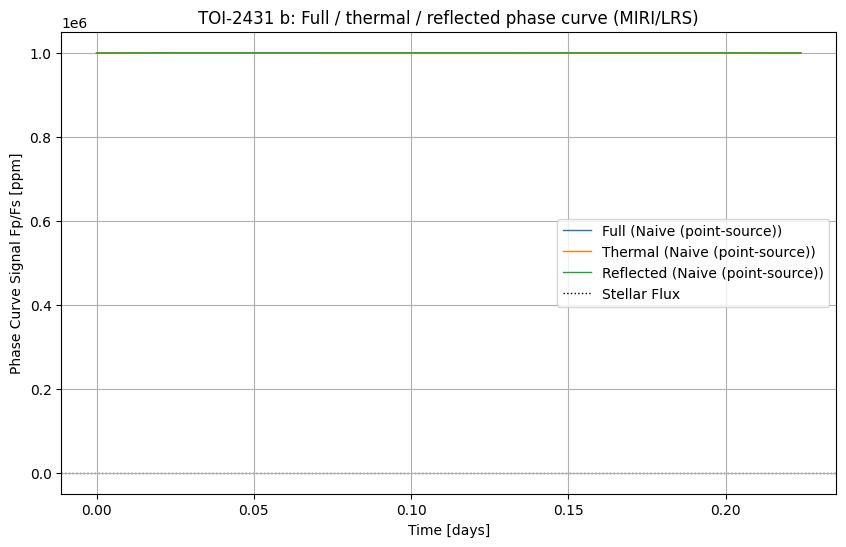

Naive (point-source)   occultation depth:  full= 206.5  thermal= 199.7  reflected=   6.7  ppm


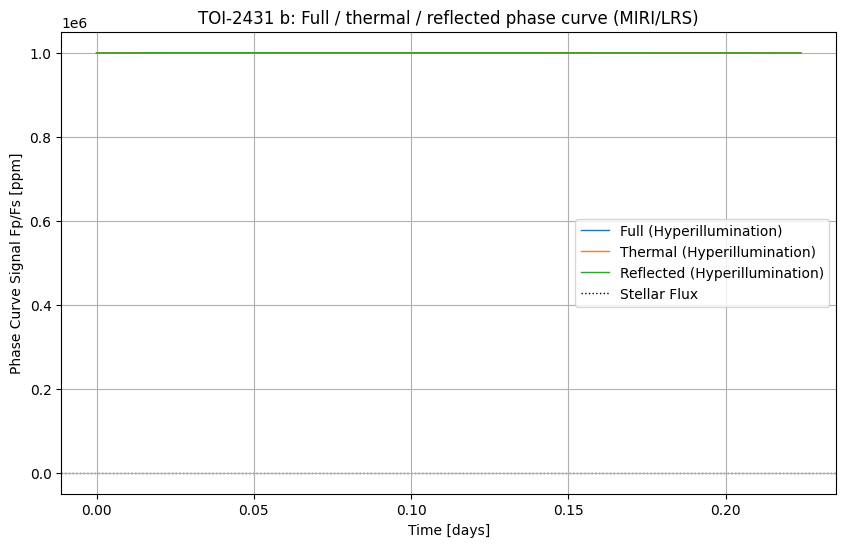

Hyperillumination      occultation depth:  full= 210.2  thermal= 203.3  reflected=   6.8  ppm


In [7]:
for model, mlabel in [("naive", "Naive (point-source)"), ("hyperillum", "Hyperillumination")]:
    t_full,  full_pc,  fp_full     = full_PhaseCurve(planet, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model=model, u_B=u_B)
    t_therm, therm_pc, fp_therm, _ = thermal_PhaseCurve(planet, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model=model, u_B=u_B)
    t_refl,  refl_pc,  fp_refl     = reflected_PhaseCurve(planet, u=u, A=A, insolation_model=model, u_B=u_B)
    
    plt.figure(figsize=(10, 6))
    plt.plot(t_full,  full_pc*1e6, color="C0", linewidth=1, label=f"Full ({mlabel})")
    plt.plot(t_therm, therm_pc*1e6, color="C1", linewidth=1, label=f"Thermal ({mlabel})")
    plt.plot(t_refl,  refl_pc*1e6, color="C2", linewidth=1, label=f"Reflected ({mlabel})")
    stellar_flux_line()
    plt.xlabel("Time [days]")
    plt.ylabel(r"Phase Curve Signal Fp/Fs [ppm]")
    plt.title(f"{planet.name}: Full / thermal / reflected phase curve ({Instrument})")
    plt.legend()
    plt.grid()
    plt.show()
    print(f"{mlabel:22s} occultation depth:  full={fp_full:6.1f}  thermal={fp_therm:6.1f}  reflected={fp_refl:6.1f}  ppm")


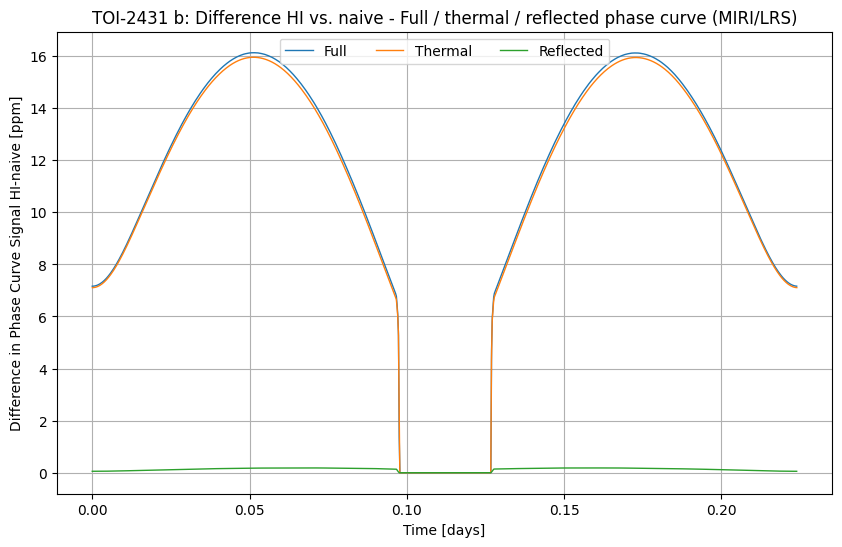

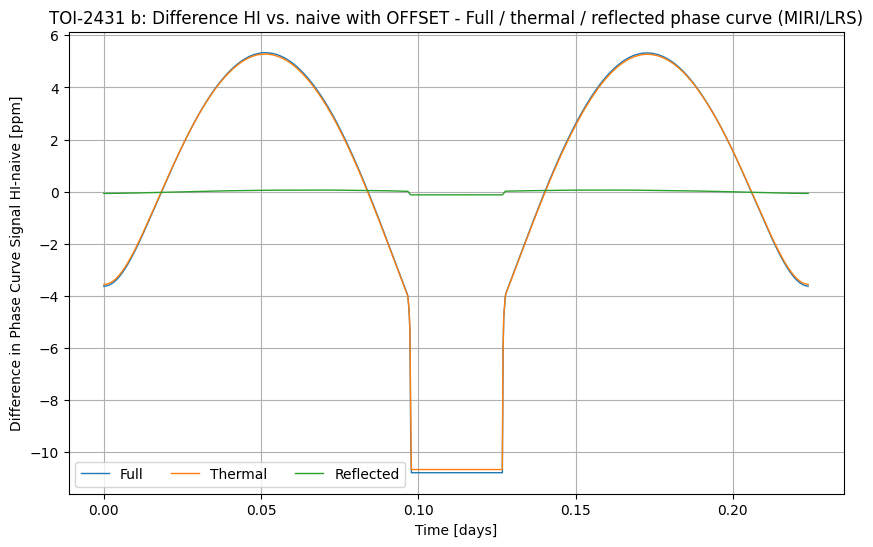

In [8]:
t_full1,  full_pc1,  fp_full1     = full_PhaseCurve(planet, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model="naive", u_B=u_B)
t_therm1, therm_pc1, fp_therm1, _ = thermal_PhaseCurve(planet, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model="naive", u_B=u_B)
t_refl1,  refl_pc1,  fp_refl1     = reflected_PhaseCurve(planet, u=u, A=A, insolation_model="naive", u_B=u_B)
t_full2,  full_pc2,  fp_full2     = full_PhaseCurve(planet, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model="hyperillum", u_B=u_B)
t_therm2, therm_pc2, fp_therm2, _ = thermal_PhaseCurve(planet, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model="hyperillum", u_B=u_B)
t_refl2,  refl_pc2,  fp_refl2     = reflected_PhaseCurve(planet, u=u, A=A, insolation_model="hyperillum", u_B=u_B)

plt.figure(figsize=(10, 6))
plt.plot(t_full1,  (full_pc2 - full_pc1)*1e6, color="C0", linewidth=1, label=f"Full")
plt.plot(t_therm1, (therm_pc2 - therm_pc1)*1e6, color="C1", linewidth=1, label=f"Thermal")
plt.plot(t_refl1,  (refl_pc2 - refl_pc1)*1e6, color="C2", linewidth=1, label=f"Reflected")
plt.xlabel("Time [days]")
plt.ylabel(r"Difference in Phase Curve Signal HI-naive [ppm]")
plt.title(f"{planet.name}: Difference HI vs. naive - Full / thermal / reflected phase curve ({Instrument})")
plt.legend(ncol=3)
plt.grid()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t_full1,  ((full_pc2-full_pc2.mean()) - (full_pc1-full_pc1.mean()))*1e6, color="C0", linewidth=1, label=f"Full")
plt.plot(t_therm1, ((therm_pc2-therm_pc2.mean()) - (therm_pc1-therm_pc1.mean()))*1e6, color="C1", linewidth=1, label=f"Thermal")
plt.plot(t_refl1,  ((refl_pc2-refl_pc2.mean()) - (refl_pc1-refl_pc1.mean()))*1e6, color="C2", linewidth=1, label=f"Reflected")
plt.xlabel("Time [days]")
plt.ylabel(r"Difference in Phase Curve Signal HI-naive [ppm]")
plt.title(f"{planet.name}: Difference HI vs. naive with OFFSET - Full / thermal / reflected phase curve ({Instrument})")
plt.legend(ncol=3)
plt.grid()
plt.show()

## Full phase curve vs. albedo ($A = A_B$)

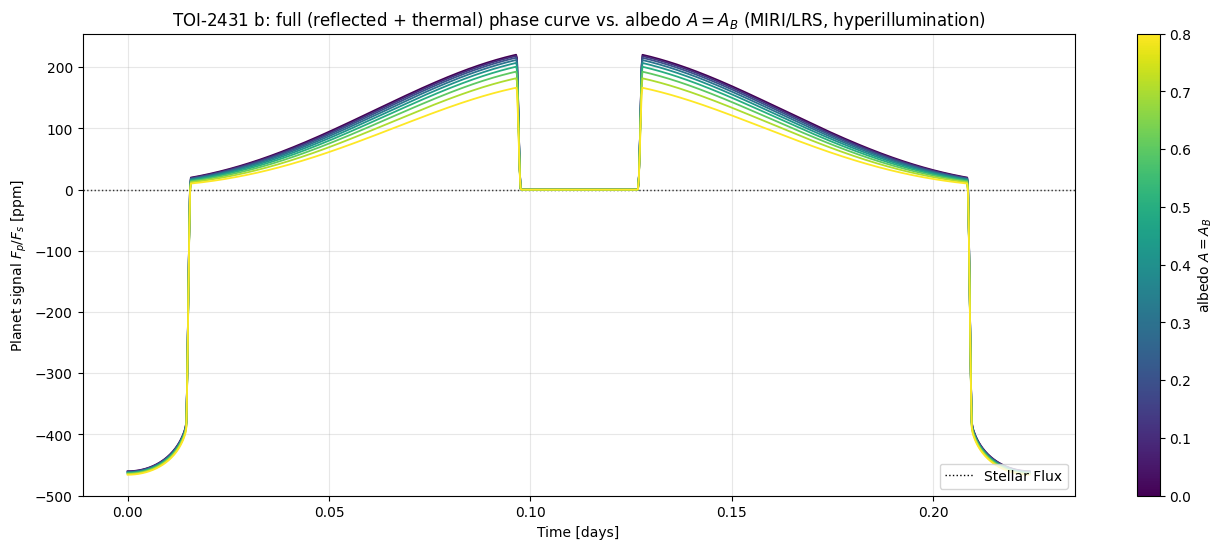

In [9]:
albedos = np.linspace(0.0, 0.8, 9)          # sweep A = A_B together (grey-Lambertian coupling)
cmap, norm = plt.cm.viridis, plt.Normalize(albedos.min(), albedos.max())

plt.figure(figsize=(16, 6))
for alb in albedos:
    t, pc, _ = full_PhaseCurve(planet, lambda_range, u=u, A=alb, A_B=alb,
                               filter_path=filter_path, insolation_model="hyperillum", u_B=u_B)
    plt.plot(t, (pc - 1) * 1e6, color=cmap(norm(alb)), linewidth=1.3)   # (pc-1): planet signal, baseline 0
stellar_flux_line(); plt.legend(loc="lower right")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
plt.colorbar(sm, ax=plt.gca(), label=r"albedo $A = A_B$")
plt.xlabel("Time [days]")
plt.ylabel(r"Planet signal $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: full (reflected + thermal) phase curve vs. albedo $A=A_B$ ({Instrument}, hyperillumination)")
plt.grid(alpha=.3)
plt.show()

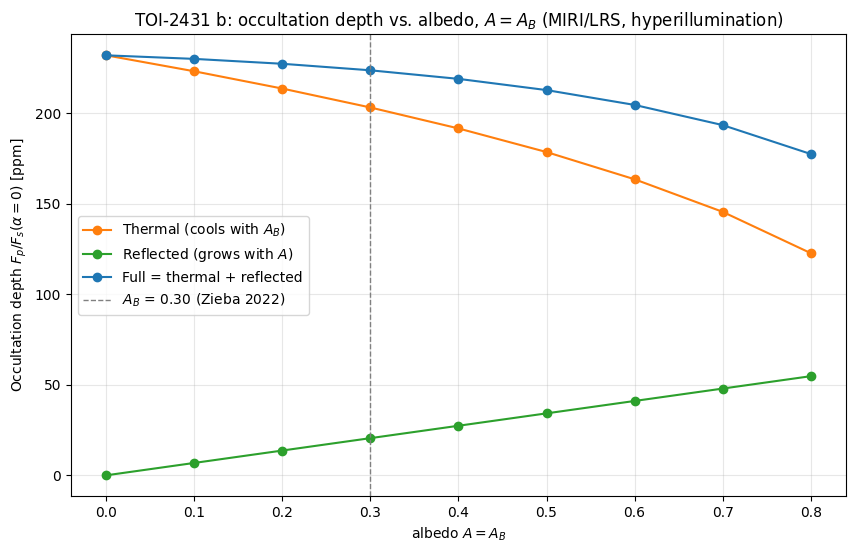

In [10]:
# Why the net effect is muted: occultation depth vs albedo, split into thermal (cools -> falls) and reflected (grows with A)
fp_therm, fp_refl = [], []
for alb in albedos:
    _, _, f_therm, _ = thermal_PhaseCurve(planet, lambda_range, u=u, A_B=alb, filter_path=filter_path, insolation_model="hyperillum", u_B=u_B)
    _, _, f_refl     = reflected_PhaseCurve(planet, u=u, A=alb, insolation_model="hyperillum", u_B=u_B)
    fp_therm.append(f_therm); fp_refl.append(f_refl)
fp_therm, fp_refl = np.array(fp_therm), np.array(fp_refl)

plt.figure(figsize=(10, 6))
plt.plot(albedos, fp_therm,           "o-", color="C1", label=r"Thermal (cools with $A_B$)")
plt.plot(albedos, fp_refl,            "o-", color="C2", label=r"Reflected (grows with $A$)")
plt.plot(albedos, fp_therm + fp_refl, "o-", color="C0", label="Full = thermal + reflected")
plt.axvline(A_B, color="0.5", ls="--", lw=1, label=rf"$A_B$ = {A_B:.2f} (Zieba 2022)")
plt.xlabel(r"albedo $A = A_B$")
plt.ylabel(r"Occultation depth $F_p/F_s(\alpha=0)$ [ppm]")
plt.title(f"{planet.name}: occultation depth vs. albedo, $A=A_B$ ({Instrument}, hyperillumination)")
plt.legend(); plt.grid(alpha=.3)
plt.show()

## Nightside flux at transit vs. instrument (hyperillumination)

At transit ($t = t_0$) the observer looks at the nightside. Under the naive (point-source) insolation the nightside is dark, but the extended star of the hyperillumination model heats a band past the $90°$ terminator, which shows up at the limb. The cell below uses `nightside_flux` (`hyperillumination_phasecurve_utils`), which evaluates the planet signal $F_p/F_s$ at transit (transit dip excluded, exact SPIDERMAN evaluation at the single time point) for every instrument in `FILTER_LAMBDA_UM`: with `unit="flux"` split into thermal and reflected parts, with `unit="temperature"` as the brightness temperature of the thermal part (`T_bright` on the band flux, the nightside counterpart of the dayside value from the occultation depth).

The naive model is the reference: its nightside is at 0 K, so its flux at transit is only the sliver of dayside visible past the pole when $i < 90°$ (exactly zero edge-on). The naive column therefore shows how much of the hyperillumination value is this geometric leak rather than real nightside emission. The brightness temperature is given for the hyperillumination model only; for naive it would only be that of the geometric leak. Expect it to fall with wavelength: the hyperillumination nightside is far from isothermal (a hot penumbral band next to a 0 K antistellar region), so the short-wavelength bands weigh the hot band more and read a higher temperature than the long-wavelength ones.


,band [µm],HI thermal [ppm],HI reflected [ppm],HI total [ppm],naive total [ppm],HI nightside T_bright [K]
instrument,,,,,,
JWST_NIRSpec.G395H_NRS1,2.9-3.7,3.0038,0.0713,3.0751,0.6552,769.2380
Spitzer/IRAC2,4.0-5.0,4.9942,0.0713,5.0655,0.9816,685.8450
JWST_NIRSpec.G395H_NRS2,3.8-5.2,4.7992,0.0713,4.8705,0.9507,691.0940
MIRI/LRS,5.0-10.5,8.5555,0.0713,8.6269,1.4638,563.0461
MIRI/F1280W,11.6-14.0,12.9330,0.0713,13.0043,1.9621,454.2470
MIRI/F1500W,13.5-16.6,14.0045,0.0713,14.0758,2.0683,427.0526
MIRI/F1800W,16.5-19.5,15.0974,0.0713,15.1687,2.1721,399.5736


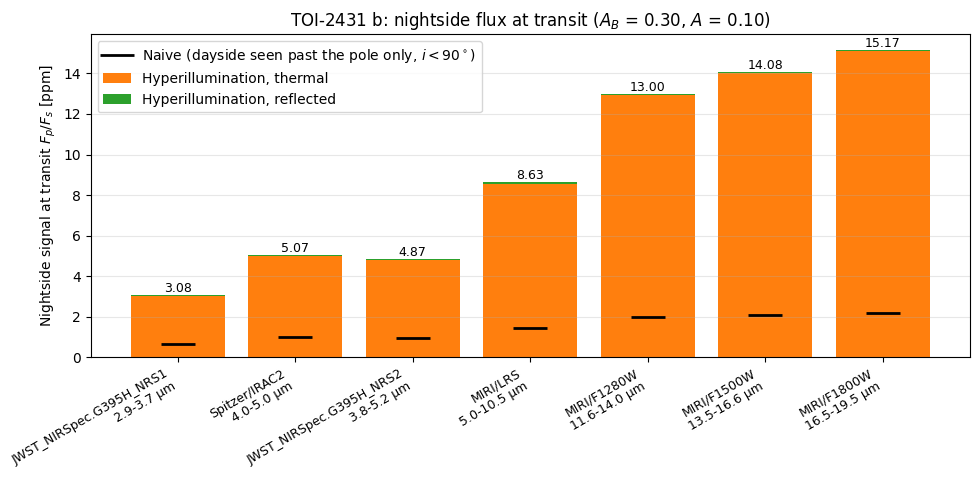

In [11]:
import pandas as pd
from joblib import Parallel, delayed
from HItargets_utils import FILTER_LAMBDA_UM

night_instruments = sorted(FILTER_LAMBDA_UM, key=lambda ins: np.mean(filter_lambda(ins)))   # ordered by band centre
night_models = ["hyperillum", "naive"]

# nightside_flux: planet signal at transit (dip excluded). unit="flux" -> (thermal, reflected) [ppm]; unit="temperature" -> brightness temperature of the thermal part [K]
night_kw = dict(u_B=u_B, A_B=A_B, A=A)
runs = [(ins, m, "flux") for ins in night_instruments for m in night_models] + [(ins, "hyperillum", "temperature") for ins in night_instruments]
out = Parallel(n_jobs=-1, backend="loky")(delayed(nightside_flux)(planet, filter_lambda(ins), m, unit=unit, filter_path=filter_loc(ins), **night_kw) for ins, m, unit in runs)
res = dict(zip(runs, out))

night_tab = pd.DataFrame([{"instrument": ins, "band [µm]": "{:.1f}-{:.1f}".format(*(1e6 * filter_lambda(ins))),
                           "HI thermal [ppm]": res[ins, "hyperillum", "flux"][0], "HI reflected [ppm]": res[ins, "hyperillum", "flux"][1],
                           "HI total [ppm]": sum(res[ins, "hyperillum", "flux"]), "naive total [ppm]": sum(res[ins, "naive", "flux"]),
                           "HI nightside T_bright [K]": res[ins, "hyperillum", "temperature"]}
                          for ins in night_instruments]).set_index("instrument")
display(night_tab.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(night_tab))
ax.bar(x, night_tab["HI thermal [ppm]"], color="C1", label="Hyperillumination, thermal")
ax.bar(x, night_tab["HI reflected [ppm]"], bottom=night_tab["HI thermal [ppm]"], color="C2", label="Hyperillumination, reflected")
ax.plot(x, night_tab["naive total [ppm]"], "k_", ms=25, mew=2, label=r"Naive (dayside seen past the pole only, $i<90^\circ$)")
for xi, v in zip(x, night_tab["HI total [ppm]"]):
    ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, [f"{ins}\n{b} µm" for ins, b in zip(night_tab.index, night_tab["band [µm]"])], rotation=30, ha="right", fontsize=9)
ax.set_ylabel(r"Nightside signal at transit $F_p/F_s$ [ppm]")
ax.set_title(f"{planet.name}: nightside flux at transit ($A_B$ = {A_B:.2f}, $A$ = {A:.2f})")
ax.legend(loc="upper left"); ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()
